In [32]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
%matplotlib inline

In [33]:
RESULTS_DIR = "raw_data"

df = pd.read_csv(f"{RESULTS_DIR}/amz_uk_price_prediction_dataset.csv")

KeyboardInterrupt: 

1. **Crosstab Analysis**:
- Create a crosstab between the product `category` and the `isBestSeller` status.
- Are there categories where being a best-seller is more prevalent? 
*Hint: one option is to calculate the proportion of best-sellers for each category and then sort the categories based on this proportion in descending order.*

In [ ]:
df.head()

,uid,asin,title,stars,reviews,price,isBestSeller,boughtInLastMonth,category
0,1,B09B96TG33,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
1,2,B01HTH3C8S,"Anker Soundcore mini, Super-Portable Bluetooth...",4.7,98099,23.99,True,0,Hi-Fi Speakers
2,3,B09B8YWXDF,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
3,4,B09B8T5VGV,"Echo Dot with clock (5th generation, 2022 rele...",4.7,7205,31.99,False,0,Hi-Fi Speakers
4,5,B09WX6QD65,Introducing Echo Pop | Full sound compact Wi-F...,4.6,1881,17.99,False,0,Hi-Fi Speakers


In [ ]:
crosstab_result = pd.crosstab(df['category'], df['isBestSeller'])
print(crosstab_result)

isBestSeller                    False  True 
category                                    
3D Printers                       247      1
3D Printing & Scanning           4065      2
Abrasive & Finishing Products     245      5
Action Cameras                   1696      1
Adapters                          251      3
...                               ...    ...
Wind Instruments                  243      7
Window Treatments                 234      5
Women                           17559    213
Women's Sports & Outdoor Shoes   1939     20
eBook Readers & Accessories       246      0

[296 rows x 2 columns]


In [ ]:
result = (pd.crosstab(df['category'], df['isBestSeller'], normalize='index')[True].sort_values(ascending=False)
)
print(result)

category
Grocery                           0.058135
Smart Home Security & Lighting    0.057692
Health & Personal Care            0.057686
Mobile Phone Accessories          0.042471
Power & Hand Tools                0.035339
                                    ...   
Bedding Collections               0.000000
CPUs                              0.000000
CD, Disc & Tape Players           0.000000
Blank Media Cases & Wallets       0.000000
eBook Readers & Accessories       0.000000
Name: True, Length: 296, dtype: float64


2. **Statistical Tests**:
    - Conduct a Chi-square test to determine if the best-seller distribution is independent of the product category.
    - Compute Cramér's V to understand the strength of association between best-seller status and category.

In [ ]:
from scipy.stats import chi2_contingency

# Chi-square test for 'MSZoning' and 'SaleCondition'
chi2_statistic, chi2_p_value, _, _ = chi2_contingency(crosstab_result)

chi2_statistic, chi2_p_value

(np.float64(36540.20270061387), np.float64(0.0))

In [ ]:
from scipy.stats.contingency import association

# Computing the association between variables in 'crosstab_result' using the "cramer" method
association(crosstab_result, method="cramer")

0.1222829439760564

The Chi-square p-value is 0.0. We concluded that variables are independent and there is enough evidence that both variables are related. This relantionship shows a small strength of 0.12. 

3. **Visualizations**:
	- Visualize the relationship between product categories and the best-seller status using a stacked bar chart.

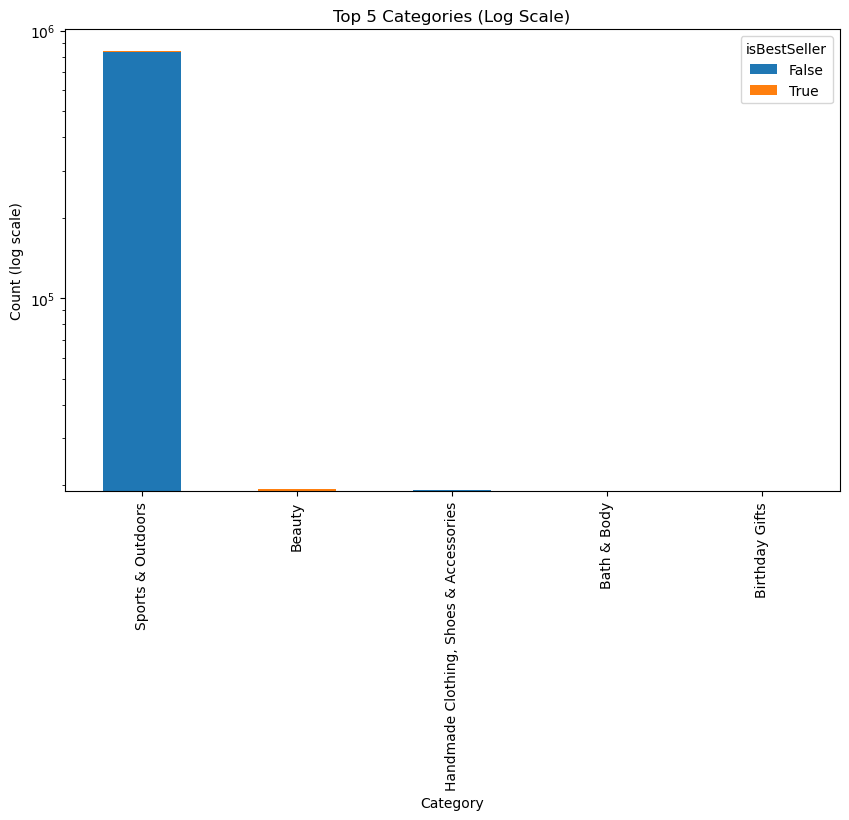

In [ ]:
# 1. Get top 10 categories by total count
top_5 = crosstab_result.sum(axis=1).nlargest(5).index

# 2. Filter the crosstab
top_crosstab = crosstab_result.loc[top_5]

# 3. Plot with log scale
top_crosstab.plot(kind="bar", stacked=True, figsize=(10,6), logy=True)

plt.title("Top 5 Categories (Log Scale)")
plt.xlabel("Category")
plt.ylabel("Count (log scale)")
plt.xticks(rotation=90)
plt.legend(title="isBestSeller")

plt.show()

### Part 2: Exploring Product Prices and Ratings Across Categories and Brands

**Objective**: Investigate how different product categories influence product prices.

0. **Preliminary Step: Remove outliers in product prices.**

	For this purpose, we can use the IQR (Interquartile Range) method. Products priced below the first quartile minus 1.5 times the IQR or above the third quartile plus 1.5 times the IQR will be considered outliers and removed from the dataset. The next steps will be done with the dataframe without outliers.
	
	*Hint: you can check the last Check For Understanding at the end of the lesson EDA Bivariate Analysis for a hint on how to do this.*


In [ ]:
stats = {"min": df["price"].min(),"max": df["price"].max(),"mean": df["price"].mean(), "range": df["price"].max() - df["price"].min(), 
         "std": df["price"].std(), "variance": df["price"].var(), "Q1": df['price'].quantile(0.25),"Q3": df['price'].quantile(0.75), "IQR": df['price'].quantile(0.75) - df['price'].quantile(0.25)}
for key, value in stats.items():
    if isinstance(value, float):
        print(f"{key}: {value:.2f}")
    else:
        print(f"{key}: {value}")

min: 0.00
max: 100000.00
mean: 89.24
range: 100000.00
std: 345.61
variance: 119445.49
Q1: 9.99
Q3: 45.99
IQR: 36.00


In [ ]:
Q1 = 9.99
Q3 = 45.99
IQR = 36.00
lower = Q1 - 1.5 * IQR
upper = Q3 + 1.5 * IQR

df_clean = df[(df['price'] >= lower) & (df['price'] <= upper)]

1. **Violin Plots**:
    - Use a violin plot to visualize the distribution of `price` across different product `categories`. Filter out the top 20 categories based on count for better visualization.
    - Which product category tends to have the highest median price? Don't filter here by top categories.

In [ ]:
df_clean.groupby("category")["price"].median()

category
3D Printers                       52.195
3D Printing & Scanning            28.580
Abrasive & Finishing Products     10.150
Action Cameras                    33.135
Adapters                           7.050
                                   ...  
Wind Instruments                  13.470
Window Treatments                 17.990
Women                             15.990
Women's Sports & Outdoor Shoes    45.990
eBook Readers & Accessories       21.990
Name: price, Length: 296, dtype: float64

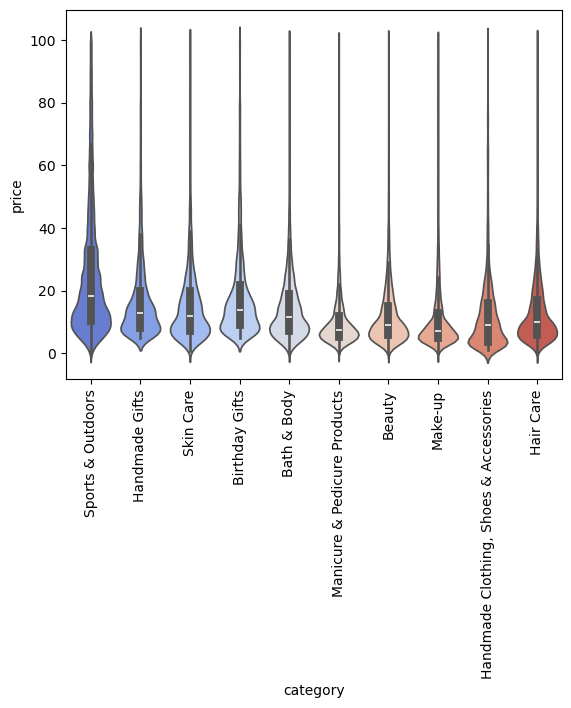

In [ ]:
top_10 = df_clean['category'].value_counts().nlargest(10).index
filtered = df_clean[df_clean['category'].isin(top_10)]

sns.violinplot(
    data=filtered,
    x='category',
    y='price',
    hue='category',
    palette="coolwarm",
    legend=False
)

plt.xticks(rotation=90)
plt.show()

The visualization shows Sports & Outdoors, Handmade Gifts, Skin Care,Birthday Gifts like
the groups with the better counts. The Sports & Outdoors has the highest median. Instead
the grouping shows the 3D Printers etc with the highest median.

2. **Bar Charts**:
    - Create a bar chart comparing the average price of products for the top 10 product categories (based on count).
    - Which product category commands the highest average price? Don't filter here by top categories.

In [ ]:
df_clean.groupby("category")["price"].mean()

category
3D Printers                       55.739722
3D Printing & Scanning            35.623904
Abrasive & Finishing Products     14.427611
Action Cameras                    38.936875
Adapters                           8.750197
                                    ...    
Wind Instruments                  18.935339
Window Treatments                 19.870633
Women                             20.408735
Women's Sports & Outdoor Shoes    49.425894
eBook Readers & Accessories       26.006952
Name: price, Length: 296, dtype: float64

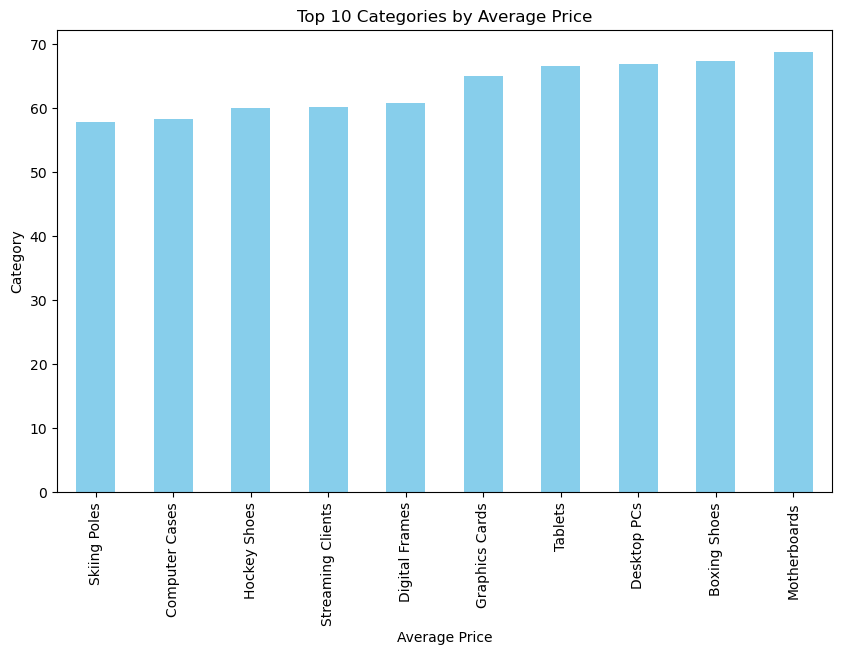

In [ ]:
# 1. Compute mean price per category
mean_price = df_clean.groupby("category")["price"].mean()

# 2. Select top 10 categories
top_10 = mean_price.sort_values(ascending=False).head(10)

# 3. Plot (horizontal is clearer)
top_10.sort_values().plot(kind="bar", figsize=(10,6), color="skyblue")

plt.title("Top 10 Categories by Average Price")
plt.xlabel("Average Price")
plt.ylabel("Category")

plt.show()

3. **Box Plots**:
    - Visualize the distribution of product `ratings` based on their `category` using side-by-side box plots. Filter out the top 10 categories based on count for better visualization.
    - Which category tends to receive the highest median rating from customers? Don't filter here by top categories.

In [ ]:
cat_star = df_clean.groupby("category")["stars"].value_counts().nlargest(10)
print(cat_star)

category                                stars
Sports & Outdoors                       0.0      567528
                                        5.0       22646
Handmade Kitchen & Dining               0.0       14607
Handmade Clothing, Shoes & Accessories  0.0       14382
Handmade Artwork                        0.0       13114
Sports & Outdoors                       4.5       12559
Handmade Jewellery                      0.0       11514
Sports & Outdoors                       4.4       11341
Birthday Gifts                          0.0       10523
Sports & Outdoors                       4.6       10360
Name: count, dtype: int64


In [ ]:
cat_star_median = df_clean.groupby("category")["stars"].median()
print(cat_star_median)

category
3D Printers                       4.1
3D Printing & Scanning            0.0
Abrasive & Finishing Products     4.5
Action Cameras                    0.0
Adapters                          4.4
                                 ... 
Wind Instruments                  4.1
Window Treatments                 4.4
Women                             4.3
Women's Sports & Outdoor Shoes    4.3
eBook Readers & Accessories       0.0
Name: stars, Length: 296, dtype: float64


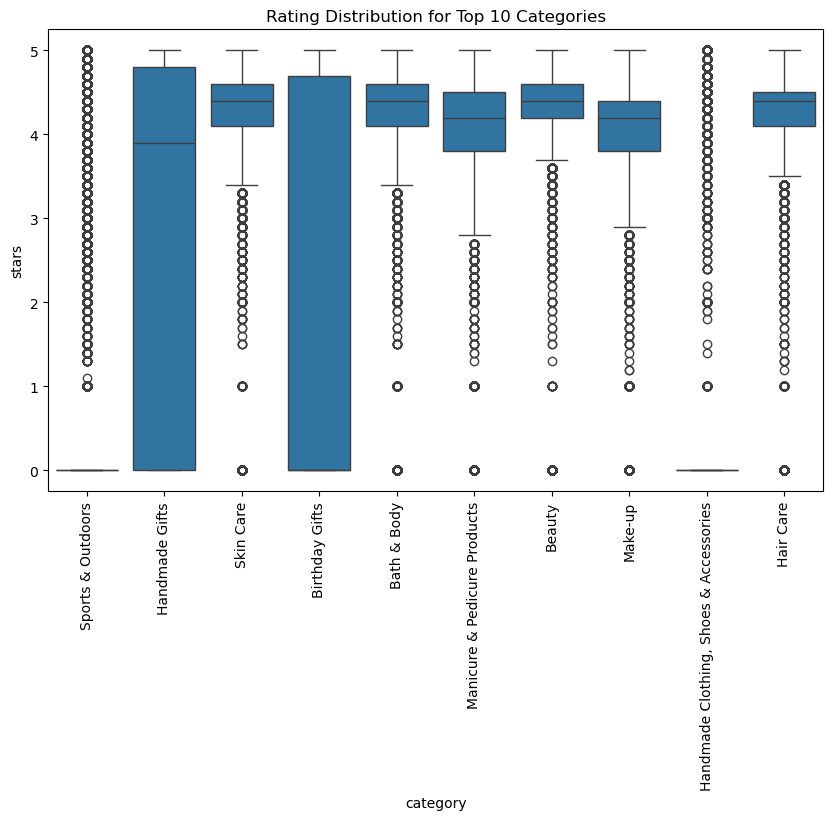

In [ ]:
# Top 10 categories by frequency
top_categories = df_clean["category"].value_counts().nlargest(10).index

filtered_df = df_clean[df_clean["category"].isin(top_categories)]

plt.figure(figsize=(10, 6))
sns.boxplot(data=filtered_df, x="category", y="stars")

plt.xticks(rotation=90)
plt.title("Rating Distribution for Top 10 Categories")
plt.show()

The main categories without filtering are 3D Printers, 3D Printing & Scanning, Abrasive & Finishing Products, Action Cameras and Adapters. Adding the top ten filtering the highest median is find in body care products mainly, products like Skin Care, Bath & Body and Beauty the highest median rating. Also those categories shows more lower outliers ratings. 

### Part 3: Investigating the Interplay Between Product Prices and Ratings

**Objective**: Analyze how product ratings (`stars`) correlate with product prices.

1. **Correlation Coefficients**:
    - Calculate the correlation coefficient between `price` and `stars`.
    - Is there a significant correlation between product price and its rating?
	
2. **Visualizations**:
    - Use a scatter plot to visualize the relationship between product rating and price. What patterns can you observe?
    - Use a correlation heatmap to visualize correlations between all numerical variables.
    - Examine if product prices typically follow a normal distribution using a QQ plot. 

In [ ]:
correlation = df['price'].corr(df['stars'])
correlation

np.float64(-0.1249067326214861)

In [ ]:
correlation = df['price'].corr(df['stars'], method='spearman')
correlation

np.float64(-0.1331642546243379)

- **Pearson Correlation**: \(-0.1249\)
- **Spearman Correlation**: \(-0.1331\)

**Insights:**

- The **Pearson correlation** of \(-0.1249\) suggests a weak and negative linear relationship between the sale price of a product and its  rating. 
higher the price lower the rating.

- The **Spearman correlation** of \(-0.1331\) indicates a weak and negative monotonic relationship between the two variables. This means that when one variable increases, the other also tends to decrease, but not necessarily at a constant rate. 

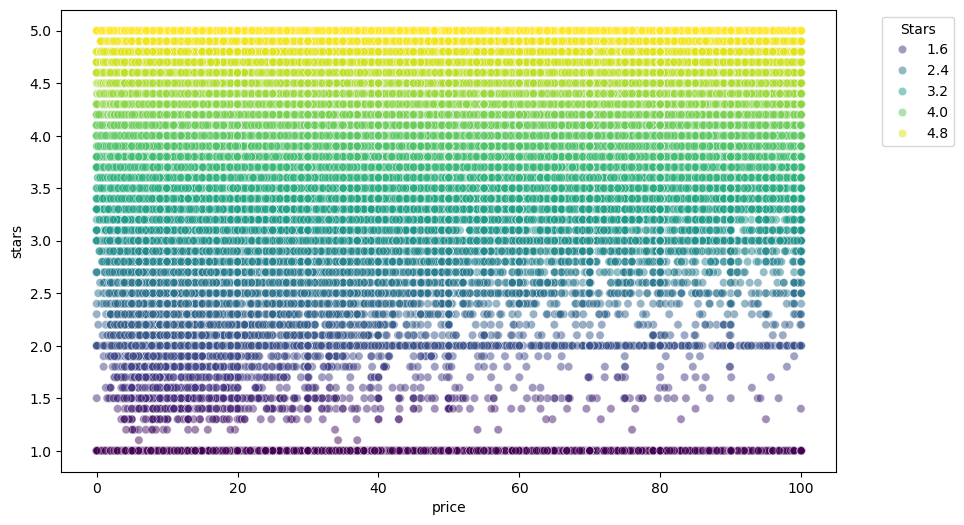

In [47]:
filtered_df = df_clean[df_clean["stars"] > 0]

plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=filtered_df,
    x="price",
    y="stars",
    hue="stars",
    palette="viridis",
    alpha=0.5
)

plt.legend(title="Stars", bbox_to_anchor=(1.05, 1))
plt.show()

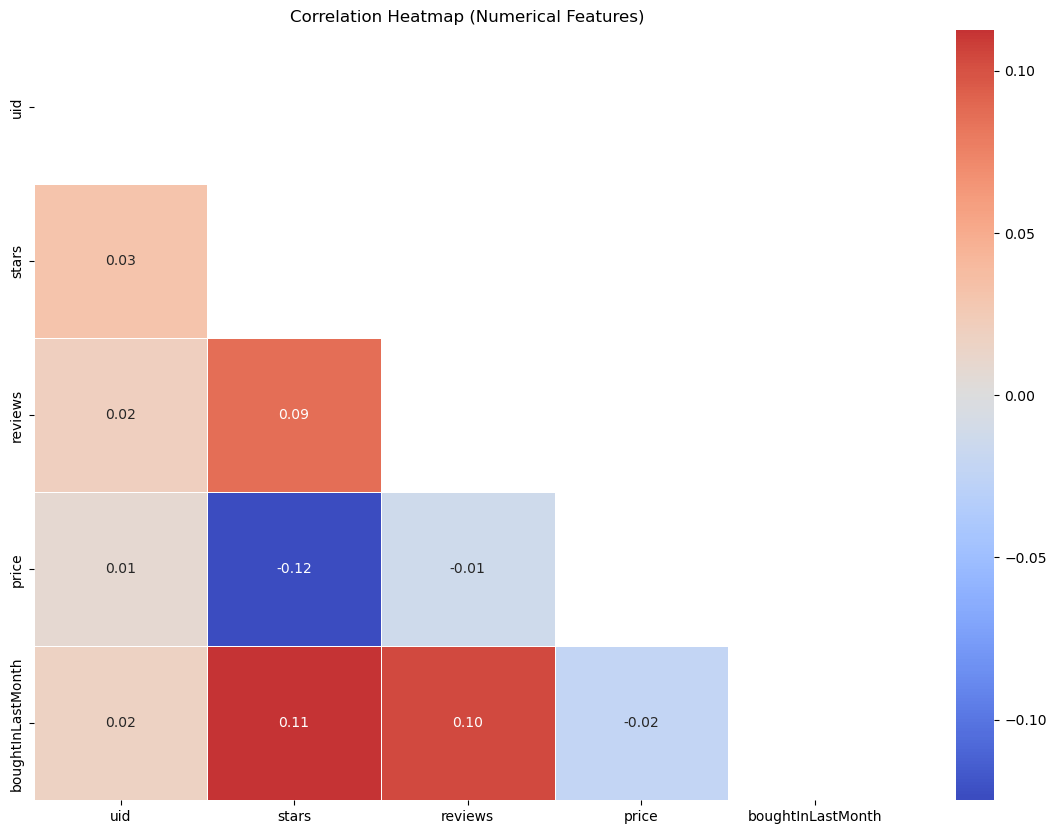

In [41]:
df_numerical = df.select_dtypes("number")

# Optional: drop columns with too many missing values
df_numerical = df_numerical.dropna(axis=1, how="all")

correlation_matrix = df_numerical.corr()

plt.figure(figsize=(14, 10))

# Mask upper triangle (removes duplicate info)
mask = np.triu(np.ones_like(correlation_matrix, dtype=bool))

sns.heatmap(
    correlation_matrix,
    mask=mask,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    linewidths=0.5
)

plt.title("Correlation Heatmap (Numerical Features)")
plt.show()

The correlation between variables is very low, showing the variables aren't influencing the behavior of the other variables.

<Figure size 800x600 with 0 Axes>

<Figure size 800x600 with 0 Axes>

<Figure size 800x600 with 0 Axes>

<Figure size 800x600 with 0 Axes>

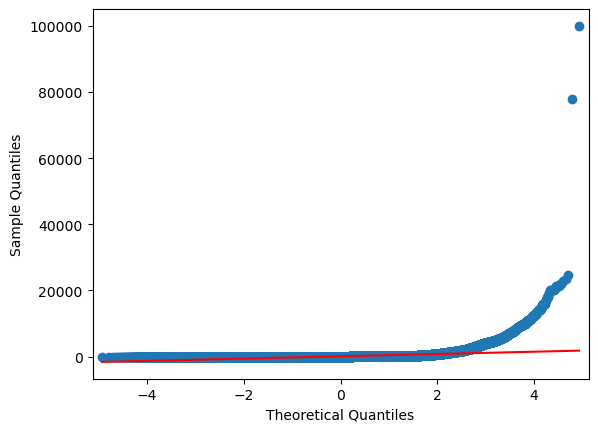

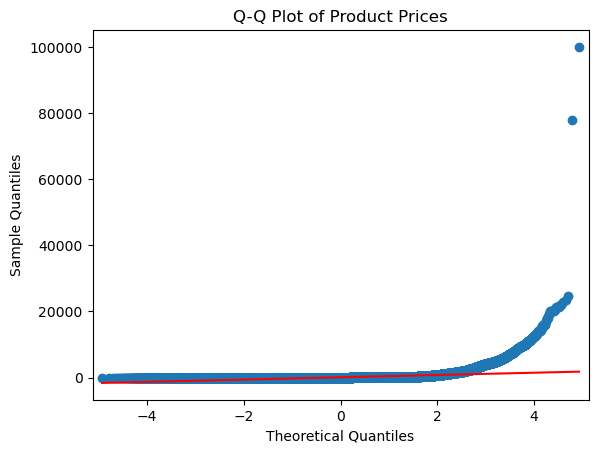

In [53]:
import statsmodels.api as sm
# Clean data
price_data = df["price"].dropna()

# Create plot
sm.qqplot(price_data, line='s')

plt.title("Q-Q Plot of Product Prices")
plt.show()


The QQ Plot using a logarithmic scale shows that most product prices are concentrated at the lower end, particularly below £50. The distribution is highly right-skewed, 
with a small number of very expensive products creating a long tail. Is difficult to interpret due to these extreme values, but applying a log scale 
improves visibility by compressing the range of higher prices.